# Predicting High-Spending International Visitors in Ghana

**Mission.** In Africa, the budgets of destination managers are small, and they don't often know who will spend the most in the local area. This project examines the ability of these factors (origin, purpose of trip, travel arrangements and length of stay) to predict high spending by a visitor. The data are of international travellers who left Ghana in 2022 and 2023. To assist in tourism targeting for the different tourism bodies, including the ones based on the Nile, like Jinja in Uganda.

**Task.** Binary classification. The target is `high_spender = 1` when a visitor's total spend (`nall`) is above the training-set median.

**Data.** Ghana International Travellers' Survey (GITS) 2022–2023, respondents file. Overnight visitors only.

**Links.** GitHub: Google Drive: `https://drive.google.com/drive/folders/1vyW-dTDuNSlTUK4Dn_VmBMEfYiyLr5MU?usp=sharing` | Video: `https://youtu.be/Q2z4FG7pI4o`

In [ ]:
# Imports and seeds so results can be reproduced
import os, random, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score,
                             accuracy_score, precision_score, recall_score, f1_score)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
for folder in ["models", "figures", "logs"]:
    os.makedirs(folder, exist_ok=True)
print("TensorFlow:", tf.__version__)

I0000 00:00:1791837354.876221     936 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791837355.036611     936 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791837356.650226     936 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0


## 1. Data loading

The raw file is stored in `data/` and is **not** committed to GitHub. The file is Latin-1 encoded because it contains a £ sign, so the default UTF-8 reader fails. I keep overnight visitors only, because same-day visitors have no accommodation spending and their spend profile is not comparable.

In [ ]:
# Load the respondents file and keep overnight visitors
DATA_PATH = "data/2022-2023GITS-respondents_Q1-Q4_v1_4.csv"
raw = pd.read_csv(DATA_PATH, low_memory=False, encoding="latin-1")
print("All respondents:", raw.shape)

df = raw[raw["vstatus"] == "2. Overnight visitors"].reset_index(drop=True)
print("Overnight visitors:", df.shape)
assert df.shape[0] >= 20000, "Below the 20,000-row requirement"
df[["nall", "Continents", "Purpose"]].head()

All respondents: (51909, 188)
Overnight visitors: (50415, 188)


,nall,Continents,Purpose
0,34328.9690,Other Afica,Business
1,3434.3401,West Afica,Business
2,1151.0000,Asia,Visiting family and friends
3,7903.0000,West Afica,Visiting family and friends
4,1370.0000,West Afica,Business


## 2. Exploratory analysis

Before modelling, I look at the spending variable and the origin of visitors. Spending is strongly right-skewed, so a log scale shows the shape better. The median is the cut-off for the target.

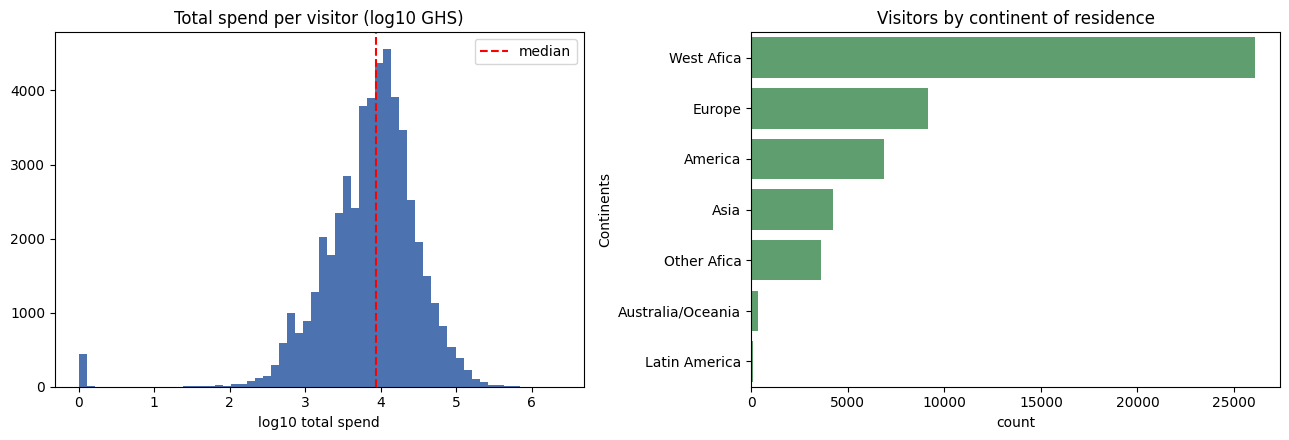

Median total spend: 8780.0


In [ ]:
# Spending distribution (log scale) and visitor origin counts
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(np.log10(df["nall"].clip(lower=1)), bins=60, color="#4C72B0")
axes[0].axvline(np.log10(df["nall"].median()), color="red", ls="--", label="median")
axes[0].set_title("Total spend per visitor (log10 GHS)")
axes[0].set_xlabel("log10 total spend"); axes[0].legend()

order = df["Continents"].value_counts().index
sns.countplot(y="Continents", data=df, order=order, ax=axes[1], color="#55A868")
axes[1].set_title("Visitors by continent of residence")
plt.tight_layout()
plt.savefig("figures/eda_spend_origin.png", dpi=150)
plt.show()
print("Median total spend:", df["nall"].median())

**Reading the plots.** On the log scale the left histogram is approximately bell-shaped, indicating that spending is approximately log-normal. The red line is the median, this means that the two categories of visitors are divided equally. The right hand graph indicates that the majority of visitors are from West Africa, here followed by Europe and America. This imbalance in origin is significant for the report as the model may be trained primarily in patterns from West Africa.

## 3. Feature selection and leakage control

The spending-related columns cannot be predictors, because the target is built from them. I drop every amount, every spending band, and every recoded spending field. I also keep only variables that describe the trip or the visitor.

In [ ]:
# Predictors: trip, purpose, origin and visitor descriptors only
CAT_COLS = ["qtr", "saq1", "month_id", "sbq3", "sbq4", "sbq6", "Heduc", "sbq8",
            "sbq9", "sbq10", "sbq12", "sbq13a", "sbq13b", "sbq14a", "sbq16",
            "sbq19", "sbq21", "sbq29a", "sbq30a", "sbq31a1", "sbq32", "sbq33",
            "sbq34", "bnight", "length_stay9", "unwto_puropse", "Purpose",
            "Continents", "Ures3", "nagrgrp"]
NUM_COLS = ["sbq15"]
df["sbq15"] = pd.to_numeric(df["sbq15"], errors="coerce")

# Columns removed because they reveal spending (the target is built from nall)
LEAKY = ["nall", "accomodation", "food_beverage", "Transport", "Recreation_culture",
         "shopping", "othersexp", "addexp_after_package", "transport_tot", "Dom_air_t",
         "sport_activity", "sbq20a", "sbq22a", "sbq24a", "sbq26a", "sbq27a", "sbq27b"]
assert not set(LEAKY) & set(CAT_COLS + NUM_COLS)
print(f"{len(CAT_COLS)} categorical and {len(NUM_COLS)} numeric predictors")

30 categorical and 1 numeric predictors


## 4. Train, validation and test split

I split the rows first, then compute the median only on the training part. Stratifying on continent keeps the origin mix the same in each split. The target is created after the split so that no information from the validation or test sets reaches the cut-off.

In [ ]:
# 70 / 15 / 15 split stratified by continent, target built with the training median
X = df[CAT_COLS + NUM_COLS]
spend = df["nall"]
strat = df["Continents"]

X_tmp, X_test, s_tmp, s_test, st_tmp, st_test = train_test_split(
    X, spend, strat, test_size=0.15, stratify=strat, random_state=SEED)
X_train, X_val, s_train, s_val = train_test_split(
    X_tmp, s_tmp, test_size=0.1765, stratify=st_tmp, random_state=SEED)

THRESH = s_train.median()
y_train = (s_train > THRESH).astype(int).values
y_val = (s_val > THRESH).astype(int).values
y_test = (s_test > THRESH).astype(int).values

print(f"Training median spend (GHS): {THRESH:,.0f}")
print("Shapes  train:", X_train.shape, " val:", X_val.shape, " test:", X_test.shape)
print("Class balance (train):", np.bincount(y_train) / len(y_train))

Training median spend (GHS): 8,702
Shapes  train: (35288, 31)  val: (7564, 31)  test: (7563, 31)
Class balance (train): [0.5 0.5]


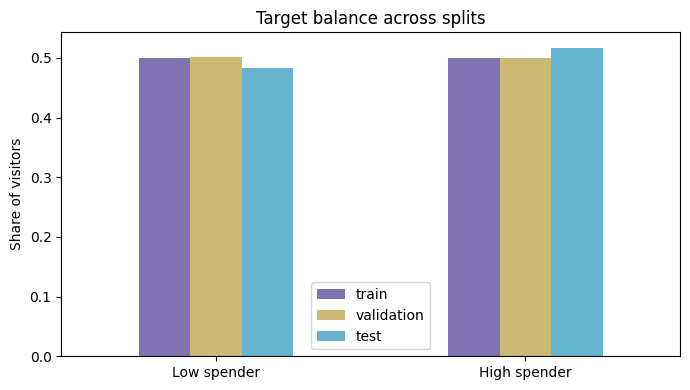

In [ ]:
# Bar chart of the target balance in each split
balance = pd.DataFrame({
    "train": np.bincount(y_train, minlength=2) / len(y_train),
    "validation": np.bincount(y_val, minlength=2) / len(y_val),
    "test": np.bincount(y_test, minlength=2) / len(y_test)}, index=["Low spender", "High spender"])
ax = balance.plot(kind="bar", figsize=(7, 4), rot=0, color=["#8172B2", "#CCB974", "#64B5CD"])
ax.set_ylabel("Share of visitors"); ax.set_title("Target balance across splits")
plt.tight_layout(); plt.savefig("figures/target_balance.png", dpi=150); plt.show()

**Reading the balance plot.** This is nearly equal split in the two classes as it is a median split. This is where accuracy is a decent yardstick. I still report ROC-AUC and precision-recall values since they don't rely on any threshold.

## 5. Preprocessing

Numeric features are imputed with the median and standardised. Categorical features are imputed with the most common value and one-hot encoded. Rare categories (fewer than 20 rows in training) are grouped together so the feature space stays manageable. The transformer is fitted on training data only.

In [ ]:
# Preprocessing pipeline fitted on the training split only
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), NUM_COLS),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=20,
                                           sparse_output=False))]), CAT_COLS),
])
X_train_p = preprocessor.fit_transform(X_train).astype(np.float32)
X_val_p = preprocessor.transform(X_val).astype(np.float32)
X_test_p = preprocessor.transform(X_test).astype(np.float32)
print("Processed feature count:", X_train_p.shape[1])

Processed feature count: 233


## 6. Traditional machine learning (Scikit-Learn)

Five traditional experiments are run. Logistic Regression is the linear baseline. Its tuned version searches over the regularisation strength. Random Forest and histogram Gradient Boosting are tree ensembles, and a linear SVM is the margin-based model. Hyperparameters are tuned with three-fold cross-validation on the **training** data only. The validation set is used to compare models.

In [ ]:
# Traditional experiments: tuning uses cross-validation on training data only
def get_score(model, X):
    # Return a ranking score and the threshold used for hard predictions
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1], 0.5
    return model.decision_function(X), 0.0

experiment_log = []
trad_models = {}

def log_run(name, family, model, params):
    score, cut = get_score(model, X_val_p)
    pred = (score >= cut).astype(int)
    experiment_log.append({
        "experiment": name, "family": family, "params": json.dumps(params, default=str),
        "val_roc_auc": roc_auc_score(y_val, score),
        "val_pr_auc": average_precision_score(y_val, score),
        "val_accuracy": accuracy_score(y_val, pred),
        "val_precision": precision_score(y_val, pred),
        "val_recall": recall_score(y_val, pred),
        "val_f1": f1_score(y_val, pred)})
    trad_models[name] = model

# T1: Logistic Regression baseline
lr_base = LogisticRegression(max_iter=2000, random_state=SEED).fit(X_train_p, y_train)
log_run("T1 Logistic baseline", "traditional", lr_base, {"C": 1.0})

# T2: Logistic Regression with C tuned
lr_grid = GridSearchCV(LogisticRegression(max_iter=2000, random_state=SEED),
                       {"C": [0.01, 0.1, 1.0, 10.0]}, cv=3, scoring="roc_auc", n_jobs=1)
lr_grid.fit(X_train_p, y_train)
log_run("T2 Logistic tuned", "traditional", lr_grid.best_estimator_, lr_grid.best_params_)

# T3: Random Forest with random search
rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=SEED, n_jobs=1),
    {"n_estimators": [100, 200], "max_depth": [8, 16, None], "min_samples_leaf": [1, 5, 20]},
    n_iter=4, cv=3, scoring="roc_auc", random_state=SEED)
rf_search.fit(X_train_p, y_train)
log_run("T3 Random Forest", "traditional", rf_search.best_estimator_, rf_search.best_params_)

# T4: Histogram Gradient Boosting with random search
hgb_search = RandomizedSearchCV(
    HistGradientBoostingClassifier(random_state=SEED),
    {"learning_rate": [0.05, 0.1, 0.2], "max_iter": [200, 400],
     "max_leaf_nodes": [31, 63], "l2_regularization": [0.0, 1.0]},
    n_iter=4, cv=3, scoring="roc_auc", random_state=SEED)
hgb_search.fit(X_train_p, y_train)
log_run("T4 Gradient Boosting", "traditional", hgb_search.best_estimator_, hgb_search.best_params_)

# T5: Linear SVM with C tuned
svm_grid = GridSearchCV(LinearSVC(max_iter=5000, random_state=SEED),
                        {"C": [0.01, 0.1, 1.0]}, cv=3, scoring="roc_auc", n_jobs=1)
svm_grid.fit(X_train_p, y_train)
log_run("T5 Linear SVM", "traditional", svm_grid.best_estimator_, svm_grid.best_params_)

pd.DataFrame(experiment_log)[["experiment", "params", "val_roc_auc", "val_f1"]]

,experiment,params,val_roc_auc,val_f1
0,T1 Logistic baseline,"{""C"": 1.0}",0.840525,0.769036
1,T2 Logistic tuned,"{""C"": 0.1}",0.840331,0.767884
2,T3 Random Forest,"{""n_estimators"": 100, ""min_samples_leaf"": 5, ""...",0.855845,0.786352
3,T4 Gradient Boosting,"{""max_leaf_nodes"": 31, ""max_iter"": 200, ""learn...",0.864044,0.783131
4,T5 Linear SVM,"{""C"": 0.01}",0.839694,0.769250


In [ ]:
# Validation comparison of the traditional experiments, ranked by ROC-AUC
trad_table = pd.DataFrame([r for r in experiment_log if r["family"] == "traditional"])
trad_table = trad_table.sort_values("val_roc_auc", ascending=False)
print(trad_table[["experiment", "val_roc_auc", "val_pr_auc", "val_accuracy",
                  "val_precision", "val_recall", "val_f1"]].round(4).to_string(index=False))

          experiment  val_roc_auc  val_pr_auc  val_accuracy  val_precision  val_recall  val_f1
T4 Gradient Boosting       0.8640      0.8517        0.7756         0.7565      0.8117  0.7831
    T3 Random Forest       0.8558      0.8423        0.7723         0.7396      0.8395  0.7864
T1 Logistic baseline       0.8405      0.8190        0.7594         0.7381      0.8026  0.7690
   T2 Logistic tuned       0.8403      0.8185        0.7581         0.7367      0.8019  0.7679
       T5 Linear SVM       0.8397      0.8180        0.7579         0.7337      0.8085  0.7693


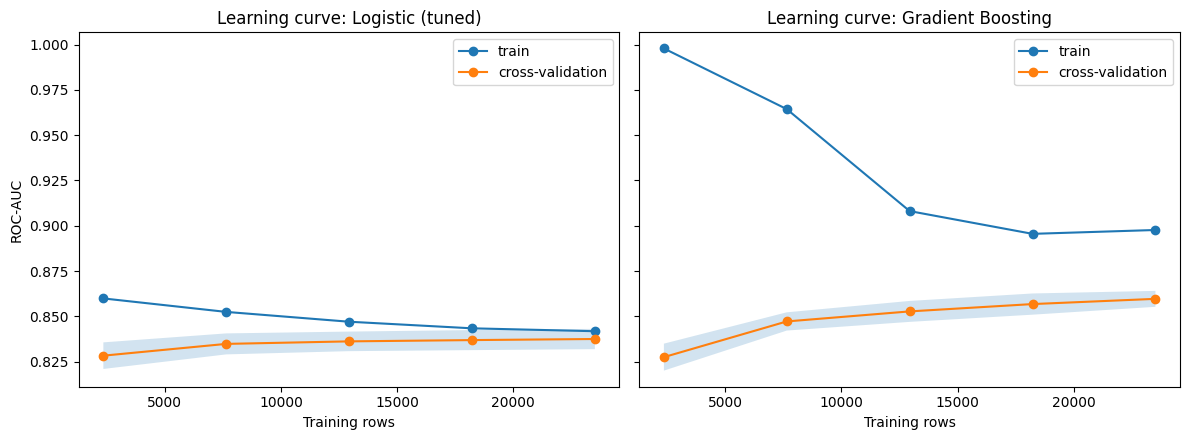

In [ ]:
# Learning curves for the best linear model and the best tree model
best_lin = lr_grid.best_estimator_
best_tree = hgb_search.best_estimator_
sizes = np.linspace(0.1, 1.0, 5)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (name, est) in zip(axes, [("Logistic (tuned)", best_lin), ("Gradient Boosting", best_tree)]):
    n, tr, va = learning_curve(est, X_train_p, y_train, train_sizes=sizes, cv=3,
                               scoring="roc_auc", n_jobs=1, random_state=SEED)
    ax.plot(n, tr.mean(1), "o-", label="train")
    ax.plot(n, va.mean(1), "o-", label="cross-validation")
    ax.fill_between(n, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.2)
    ax.set_title(f"Learning curve: {name}"); ax.set_xlabel("Training rows"); ax.legend()
axes[0].set_ylabel("ROC-AUC")
plt.tight_layout(); plt.savefig("figures/learning_curves_traditional.png", dpi=150); plt.show()

**Reading the learning curves.** The lines are averages over 3 folds, and the grey-shaded band is one standard deviation. As the number of data increases the training and validation lines do not converge, the model is overfitting. Both the train and validation lines are low and close to each other, it is underfitting and additional data will not suffice. The gradient boosting model would keep on improving from additional rows of data, unlike the logistic model.

In [ ]:
# Save the best traditional model and the preprocessor
best_trad_name = trad_table.iloc[0]["experiment"]
best_trad = trad_models[best_trad_name]
joblib.dump(best_trad, "models/best_traditional.joblib")
joblib.dump(preprocessor, "models/preprocessor.joblib")
print("Saved best traditional model:", best_trad_name)

Saved best traditional model: T4 Gradient Boosting


## 7. Deep learning (TensorFlow / Keras)

The network uses the Functional API and reads data through a `tf.data` pipeline with shuffling, batching, caching and prefetching. Four configurations are compared. They differ in width, depth, dropout and learning rate. Early stopping on validation ROC-AUC prevents overtraining. TensorBoard logs are written to `logs/`.

In [ ]:
# tf.data pipelines for training, validation and test
BATCH = 256

def make_dataset(X, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y.astype(np.float32)))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).cache().prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_train_p, y_train, shuffle=True)
val_ds = make_dataset(X_val_p, y_val)
test_ds = make_dataset(X_test_p, y_test)

In [ ]:
# Functional API model; width, depth, dropout and learning rate are arguments
def build_model(input_dim, units=(128, 64), dropout=0.3, lr=1e-3):
    inputs = tf.keras.Input(shape=(input_dim,), name="features")
    x = inputs
    for i, u in enumerate(units):
        x = tf.keras.layers.Dense(u, activation="relu", name=f"dense_{i}")(x)
        x = tf.keras.layers.BatchNormalization(name=f"bn_{i}")(x)
        x = tf.keras.layers.Dropout(dropout, name=f"drop_{i}")(x)
    outputs = tf.keras.layers.Dense(1, activation="sigmoid", name="prob")(x)
    model = tf.keras.Model(inputs, outputs, name="spend_classifier")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.AUC(name="roc_auc"),
                 tf.keras.metrics.AUC(curve="PR", name="pr_auc")])
    return model

In [ ]:
# Four deep experiments; each gets its own TensorBoard log folder
dl_configs = {
    "D1 wide":        dict(units=(256, 128), dropout=0.3, lr=1e-3),
    "D2 narrow":      dict(units=(64, 32),   dropout=0.2, lr=1e-3),
    "D3 high lr":     dict(units=(128, 64),  dropout=0.3, lr=1e-2),
    "D4 deep, slow":  dict(units=(128, 64, 32), dropout=0.4, lr=3e-4),
}
histories, dl_models = {}, {}

for name, cfg in dl_configs.items():
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(X_train_p.shape[1], **cfg)
    es = tf.keras.callbacks.EarlyStopping(monitor="val_roc_auc", mode="max",
                                          patience=4, restore_best_weights=True)
    tb = tf.keras.callbacks.TensorBoard(log_dir=f"logs/{name.replace(' ', '_')}")
    hist = model.fit(train_ds, validation_data=val_ds, epochs=30,
                     callbacks=[es, tb], verbose=0)
    histories[name] = hist.history
    dl_models[name] = model
    best_val = max(hist.history["val_roc_auc"])
    print(f"{name}: best val ROC-AUC = {best_val:.4f}, epochs run = {len(hist.epoch)}")
    experiment_log.append({
        "experiment": name, "family": "deep", "params": json.dumps(cfg),
        "val_roc_auc": best_val,
        "val_pr_auc": max(hist.history["val_pr_auc"]),
        "val_accuracy": np.nan, "val_precision": np.nan,
        "val_recall": np.nan, "val_f1": np.nan})

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


D1 wide: best val ROC-AUC = 0.8598, epochs run = 10


D2 narrow: best val ROC-AUC = 0.8576, epochs run = 17


D3 high lr: best val ROC-AUC = 0.8570, epochs run = 16


D4 deep, slow: best val ROC-AUC = 0.8552, epochs run = 30


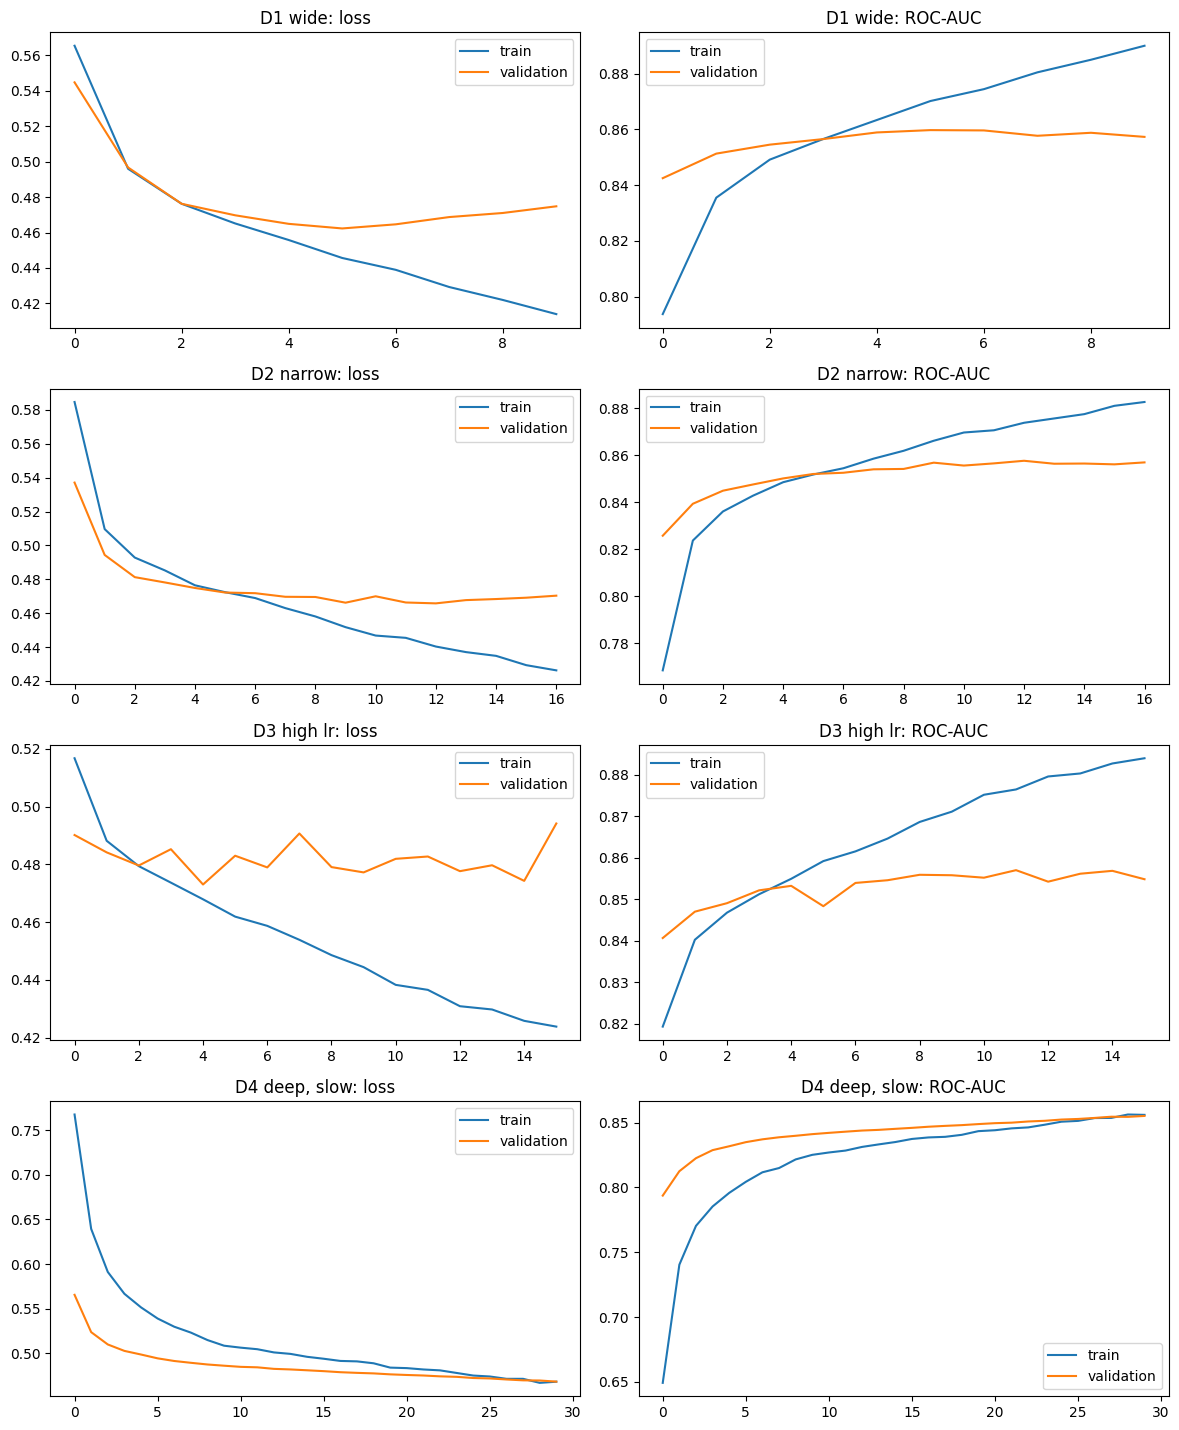

In [ ]:
# Training and validation curves for each deep experiment
fig, axes = plt.subplots(len(dl_configs), 2, figsize=(12, 3.6 * len(dl_configs)))
for row, (name, h) in enumerate(histories.items()):
    axes[row, 0].plot(h["loss"], label="train"); axes[row, 0].plot(h["val_loss"], label="validation")
    axes[row, 0].set_title(f"{name}: loss"); axes[row, 0].legend()
    axes[row, 1].plot(h["roc_auc"], label="train"); axes[row, 1].plot(h["val_roc_auc"], label="validation")
    axes[row, 1].set_title(f"{name}: ROC-AUC"); axes[row, 1].legend()
plt.tight_layout(); plt.savefig("figures/learning_curves_deep.png", dpi=150); plt.show()

**Reading the deep learning curves.** Loss and ROC-AUC are displayed in the left and right columns respectively, with training in blue and validation in orange. If the validation score is not improving then the gap between the validation score and the training score is increasing, and the first time the gap did not improve, the best validation score was the same time. The learning-rate run is the one that is important to monitor: if the curves in this run do not settle, then the optimiser has chosen a step size that is too large for the learning rate.

In [ ]:
# Pick the best deep experiment by validation ROC-AUC and save it
best_dl_name = max(histories, key=lambda k: max(histories[k]["val_roc_auc"]))
best_dl = dl_models[best_dl_name]
best_dl.save("models/best_deep.h5")
print("Saved best deep model:", best_dl_name)

Saved best deep model: D1 wide


## 8. Test-set evaluation

The test set was never used for training, tuning or early stopping. Every model is scored on it once. The best model from each family is compared, and the full set of experiment results is saved for the report.

In [ ]:
# Test metrics for all traditional models and all deep models
test_rows, test_scores = [], {}

for name, model in trad_models.items():
    score, cut = get_score(model, X_test_p)
    pred = (score >= cut).astype(int)
    test_scores[name] = score
    test_rows.append({"Model": name, "ROC-AUC": roc_auc_score(y_test, score),
                      "PR-AUC": average_precision_score(y_test, score),
                      "Accuracy": accuracy_score(y_test, pred),
                      "Precision": precision_score(y_test, pred),
                      "Recall": recall_score(y_test, pred),
                      "F1": f1_score(y_test, pred)})

for name, model in dl_models.items():
    score = model.predict(test_ds, verbose=0).ravel()
    pred = (score >= 0.5).astype(int)
    test_scores[name] = score
    test_rows.append({"Model": name, "ROC-AUC": roc_auc_score(y_test, score),
                      "PR-AUC": average_precision_score(y_test, score),
                      "Accuracy": accuracy_score(y_test, pred),
                      "Precision": precision_score(y_test, pred),
                      "Recall": recall_score(y_test, pred),
                      "F1": f1_score(y_test, pred)})

final_table = pd.DataFrame(test_rows).sort_values("ROC-AUC", ascending=False).round(4)
print(final_table.to_string(index=False))

               Model  ROC-AUC  PR-AUC  Accuracy  Precision  Recall     F1
T4 Gradient Boosting   0.8665  0.8610    0.7857     0.7753  0.8243 0.7991
             D1 wide   0.8619  0.8560    0.7776     0.7644  0.8238 0.7930
           D2 narrow   0.8606  0.8546    0.7775     0.7607  0.8309 0.7943
       D4 deep, slow   0.8604  0.8544    0.7767     0.7669  0.8161 0.7907
          D3 high lr   0.8594  0.8557    0.7728     0.7445  0.8535 0.7953
    T3 Random Forest   0.8581  0.8539    0.7751     0.7544  0.8376 0.7938
   T2 Logistic tuned   0.8433  0.8309    0.7665     0.7557  0.8102 0.7820
T1 Logistic baseline   0.8430  0.8305    0.7658     0.7548  0.8102 0.7815
       T5 Linear SVM   0.8427  0.8308    0.7661     0.7521  0.8169 0.7831


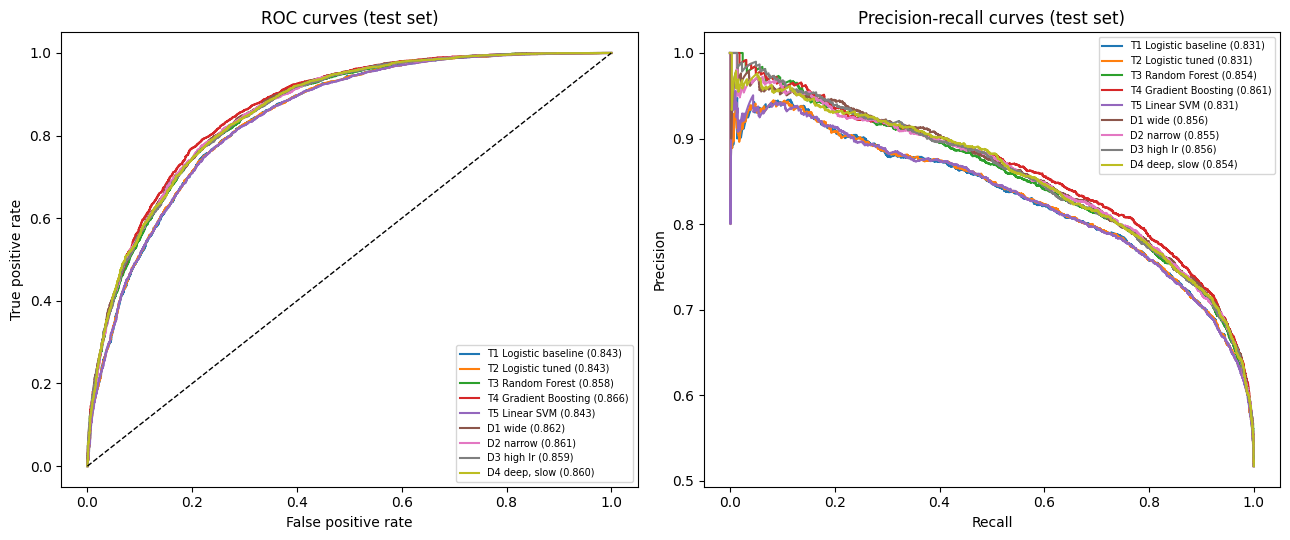

In [ ]:
# ROC and precision-recall curves for the models on the test set
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5))
for name, s in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    ax1.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, s):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, s)
    ax2.plot(rec, prec, label=f"{name} ({average_precision_score(y_test, s):.3f})")
ax1.plot([0, 1], [0, 1], "k--", lw=1)
ax1.set_title("ROC curves (test set)"); ax1.set_xlabel("False positive rate"); ax1.set_ylabel("True positive rate")
ax2.set_title("Precision-recall curves (test set)"); ax2.set_xlabel("Recall"); ax2.set_ylabel("Precision")
ax1.legend(fontsize=7); ax2.legend(fontsize=7)
plt.tight_layout(); plt.savefig("figures/roc_pr_test.png", dpi=150); plt.show()

**Reading the ROC and PR plots.** A curve closer to the top-left corner ranks high spenders above low spenders more reliably. The dashed diagonal is a random guess. Because the classes are balanced, the PR curves and ROC curves tell a similar story here, but the PR plot is more sensitive to the precision a tourism body would actually get when it targets the top-ranked visitors.

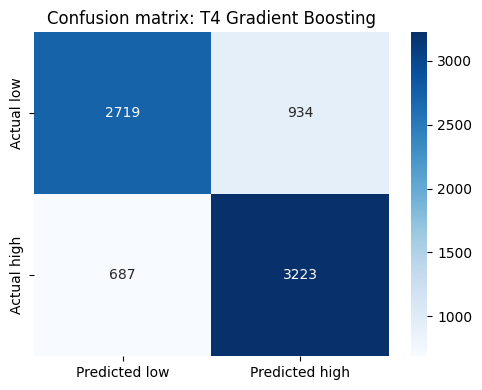

              precision    recall  f1-score   support

         low      0.798     0.744     0.770      3653
        high      0.775     0.824     0.799      3910

    accuracy                          0.786      7563
   macro avg      0.787     0.784     0.785      7563
weighted avg      0.786     0.786     0.785      7563



In [ ]:
# Confusion matrix and classification report for the best overall model
top_name = final_table.iloc[0]["Model"]
top_score = test_scores[top_name]
top_pred = (top_score >= (0.0 if top_name.startswith("T5") else 0.5)).astype(int)

cm = confusion_matrix(y_test, top_pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["Predicted low", "Predicted high"],
            yticklabels=["Actual low", "Actual high"])
ax.set_title(f"Confusion matrix: {top_name}")
plt.tight_layout(); plt.savefig("figures/confusion_top_model.png", dpi=150); plt.show()
print(classification_report(y_test, top_pred, target_names=["low", "high"], digits=3))

**Reading the confusion matrix.** On the diagonal, the predictions are correct. The top right cell represents visitors who were classified as high spenders but were not in fact high spenders and the bottom left cell represents visitors who were classified as high spenders but were not. The mistake for a tourism body is almost always the one that overlook a high spender, since this means that a valuable segment is not targeted.

## 8b. Feature checks: importance and ablation

Two checks test whether the model depends on a few variables. Permutation importance shuffles one column at a time and measures the drop in validation ROC-AUC. Ablation retrains the model with a column removed. The two methods can disagree when features are correlated, so I treat the retraining result as the stronger evidence.

In [ ]:
# Permutation importance on the validation set for the best traditional model
rng = np.random.default_rng(SEED)
base_auc = roc_auc_score(y_val, best_trad.predict_proba(preprocessor.transform(X_val))[:, 1])
perm_rows = []
for col in CAT_COLS + NUM_COLS:
    drops = []
    for _ in range(3):
        Xp = X_val.copy()
        Xp[col] = rng.permutation(Xp[col].values)
        drops.append(base_auc - roc_auc_score(y_val, best_trad.predict_proba(preprocessor.transform(Xp))[:, 1]))
    perm_rows.append((col, np.mean(drops)))
perm_df = pd.DataFrame(perm_rows, columns=["feature", "mean_auc_drop"]).sort_values("mean_auc_drop", ascending=False)
perm_df.to_csv("permutation_importance.csv", index=False)
print("Baseline validation ROC-AUC:", round(base_auc, 4))
perm_df.head(10).round(4)

Baseline validation ROC-AUC: 0.864


,feature,mean_auc_drop
30,sbq15,0.0445
8,sbq9,0.0260
3,sbq3,0.0255
24,length_stay9,0.0214
27,Continents,0.0205
7,sbq8,0.0121
1,saq1,0.0082
15,sbq19,0.0079
13,sbq14a,0.0061
2,month_id,0.0061


In [ ]:
# Ablation: retrain the boosting model with feature groups removed (same split, same settings)
def ablate(cat, num, label):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=20,
                                               sparse_output=False))]), cat)])
    Xtr = pre.fit_transform(X_train[cat + num]).astype(np.float32)
    Xv = pre.transform(X_val[cat + num]).astype(np.float32)
    m = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, max_leaf_nodes=31,
                                       l2_regularization=1.0, random_state=SEED).fit(Xtr, y_train)
    return {"Feature set": label, "Val ROC-AUC": round(roc_auc_score(y_val, m.predict_proba(Xv)[:, 1]), 4)}

short_cat = [c for c in CAT_COLS if c not in ["sbq3", "length_stay9"]]
ablation = pd.DataFrame([
    ablate(CAT_COLS, NUM_COLS, "All predictors"),
    ablate(CAT_COLS, [], "Without sbq15"),
    ablate(short_cat, NUM_COLS, "Without length-of-stay variables"),
    ablate(short_cat, [], "Without sbq15 and length-of-stay variables")])
ablation.to_csv("ablation_results.csv", index=False)
ablation

,Feature set,Val ROC-AUC
0,All predictors,0.8627
1,Without sbq15,0.8605
2,Without length-of-stay variables,0.8418
3,Without sbq15 and length-of-stay variables,0.8277


**Reading the feature checks.** The permutation ranking puts `sbq15` first, but the ablation shows that removing it costs very little once the model is retrained. Permutation importance measures how much a trained model relies on a column, so correlated features can make it look more important than it is. Removing the length-of-stay variables causes a clear drop, which means the model's main signal is how long people stayed. That is intuitive, but it also means the model partly predicts spending from duration.

## 9. Saving results

Every experiment is saved to a CSV so that the results table in the report can be traced back to this notebook.

In [ ]:
# Write the experiment log and the test results to CSV
exp_df = pd.DataFrame(experiment_log)
exp_df.to_csv("experiment_log.csv", index=False)
final_table.to_csv("test_results.csv", index=False)
print(exp_df[["experiment", "family", "val_roc_auc", "val_pr_auc"]].round(4).to_string(index=False))

          experiment      family  val_roc_auc  val_pr_auc
T1 Logistic baseline traditional       0.8405      0.8190
   T2 Logistic tuned traditional       0.8403      0.8185
    T3 Random Forest traditional       0.8558      0.8423
T4 Gradient Boosting traditional       0.8640      0.8517
       T5 Linear SVM traditional       0.8397      0.8180
             D1 wide        deep       0.8598      0.8465
           D2 narrow        deep       0.8576      0.8425
          D3 high lr        deep       0.8570      0.8436
       D4 deep, slow        deep       0.8552      0.8414


## 10. Conclusion

The results reveal the level of success that the visitor profile achieves at predicting high spend, as well as the models that proved most successful, and the areas in which the models were inaccurate. The primary constraints are the sample (air arrivals dominate, and it is limited to Ghana), the fact that some tourists' spending is missing, and the choice of a median rather than a fact about tourism. The entire discussion is given in the written report.